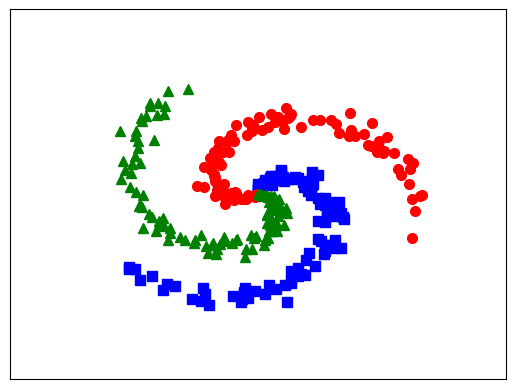

iter 0, loss: 1.098758
iter 1000, loss: 0.108211
iter 2000, loss: 0.048509
iter 3000, loss: 0.034962
iter 4000, loss: 0.029074
iter 5000, loss: 0.025662
iter 6000, loss: 0.023442
iter 7000, loss: 0.021828
iter 8000, loss: 0.020606
iter 9000, loss: 0.019666
training accuracy: 99.33 %


In [1]:
# Multi-layer Perceptron và Backpropagation
from __future__ import division, print_function, unicode_literals
import math
import numpy as np
import matplotlib.pyplot as plt

N = 100 # number of points per class
d0 = 2 # dimensionality
C = 3 # number of classes
X = np.zeros((d0, N*C)) # data matrix (each row = single example)
y = np.zeros(N*C, dtype='uint8') # class labels

for j in range(C):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[:,ix] = np.c_[r*np.sin(t), r*np.cos(t)].T
  y[ix] = j
# lets visualize the data:
# plt.scatter(X[:N, 0], X[:N, 1], c=y[:N], s=40, cmap=plt.cm.Spectral)

plt.plot(X[0, :N], X[1, :N], 'bs', markersize = 7);
plt.plot(X[0, N:2*N], X[1, N:2*N], 'ro', markersize = 7);
plt.plot(X[0, 2*N:], X[1, 2*N:], 'g^', markersize = 7);
# plt.axis('off')
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5])
cur_axes = plt.gca()
cur_axes.axes.get_xaxis().set_ticks([])
cur_axes.axes.get_yaxis().set_ticks([])

plt.savefig('EX.png', bbox_inches='tight', dpi = 600)
plt.show()

def softmax(V):
    e_V = np.exp(V - np.max(V, axis = 0, keepdims = True))
    Z = e_V / e_V.sum(axis = 0)
    return Z

## One-hot coding
from scipy import sparse
def convert_labels(y, C = 3):
    Y = sparse.coo_matrix((np.ones_like(y),
        (y, np.arange(len(y)))), shape = (C, len(y))).toarray()
    return Y

# cost or loss function
def cost(Y, Yhat):
    return -np.sum(Y*np.log(Yhat))/Y.shape[1]
d0 = 2
d1 = h = 100 # size of hidden layer
d2 = C = 3
# initialize parameters randomly
W1 = 0.01*np.random.randn(d0, d1)
b1 = np.zeros((d1, 1))
W2 = 0.01*np.random.randn(d1, d2)
b2 = np.zeros((d2, 1))

Y = convert_labels(y, C)
N = X.shape[1]
eta = 1 # learning rate
for i in range(10000):
    ## Feedforward
    Z1 = np.dot(W1.T, X) + b1
    A1 = np.maximum(Z1, 0)
    Z2 = np.dot(W2.T, A1) + b2
    Yhat = softmax(Z2)

    # print loss after each 1000 iterations
    if i %1000 == 0:
        # compute the loss: average cross-entropy loss
        loss = cost(Y, Yhat)
        print("iter %d, loss: %f" %(i, loss))

    # backpropagation
    E2 = (Yhat - Y )/N
    dW2 = np.dot(A1, E2.T)
    db2 = np.sum(E2, axis = 1, keepdims = True)
    E1 = np.dot(W2, E2)
    E1[Z1 <= 0] = 0 # gradient of ReLU
    dW1 = np.dot(X, E1.T)
    db1 = np.sum(E1, axis = 1, keepdims = True)

    # Gradient Descent update
    W1 += -eta*dW1
    b1 += -eta*db1
    W2 += -eta*dW2
    b2 += -eta*db2

Z1 = np.dot(W1.T, X) + b1
A1 = np.maximum(Z1, 0)
Z2 = np.dot(W2.T, A1) + b2
predicted_class = np.argmax(Z2, axis=0)
print('training accuracy: %.2f %%' % (100*np.mean(predicted_class == y)))

# Giải thích Code và Nhận xét kết quả huấn luyện

Dưới đây là phần phiên giải chi tiết về chương trình Multi-layer Perceptron (MLP) sử dụng lan truyền ngược (Backpropagation) và nhận xét kết quả mô hình.

---

## 1. Phiên giải thuật toán và Code

Chương trình xây dựng một mạng thần kinh nhân tạo (Neural Network) với **1 lớp ẩn** để phân loại dữ liệu phi tuyến (spiral dataset) gồm 3 lớp khác nhau.

### Bước 1: Khởi tạo dữ liệu và trực quan hóa
- **Dữ liệu `X` và nhãn `y`**: Tạo ra một tập dữ liệu phân tán theo hình xoắn ốc (spiral) gồm 3 lớp ứng với các màu xanh dương (`bs`), đỏ (`ro`) và xanh lá (`g^`).
- Mỗi lớp có `N = 100` điểm, không gian 2 chiều ($d_0 = 2$). Tổng cộng mạng nhận đầu vào là một ma trận kích thước `(2, 300)`.

### Bước 2: Khởi tạo các hàm phụ trợ
- **Hàm `softmax`**: Chuyển đổi các giá trị đầu ra (logits) thành phân phối xác suất cho các lớp. Kỹ thuật trừ `np.max(V)` giúp tránh hiện tượng tràn số (overflow).
- **Hàm `convert_labels`**: Chuyển đổi nhãn lớp $y$ từ dạng số nguyên (0, 1, 2) sang ma trận One-hot encoding có kích thước `(3, 300)`.
- **Hàm `cost`**: Tính toán hàm mất mát Cross-Entropy giữa phân phối thực tế `Y` và dự đoán `Yhat`.

### Bước 3: Khởi tạo tham số mạng
- Lớp ẩn có kích thước $d_1 = 100$ và lớp đầu ra có kích thước $d_2 = 3$.
- Trọng số $W_1, W_2$ được khởi tạo ngẫu nhiên theo phân phối chuẩn với độ lệch chuẩn nhỏ ($0.01$).
- Độ lệch $b_1, b_2$ được khởi tạo bằng 0.

### Bước 4: Vòng lặp huấn luyện (Gradient Descent & Backpropagation)
Với mỗi epoch trong số 10,000 lần lặp:
1. **Lan truyền xuôi (Feedforward)**:
   - Tính toán đầu ra lớp ẩn: $Z_1 = W_1^T X + b_1$.
   - Áp dụng hàm kích hoạt phi tuyến **ReLU**: $A_1 = \max(Z_1, 0)$.
   - Tính toán đầu ra lớp quyết định: $Z_2 = W_2^T A_1 + b_2$.
   - Áp dụng **Softmax** để thu được xác suất dự đoán: $\hat{Y} = \text{softmax}(Z_2)$.
2. **Lan truyền ngược (Backpropagation)**:
   - Tính sai số tại đầu ra: $E_2 = \frac{\hat{Y} - Y}{N}$.
   - Tính gradient cho tầng 2: $dW_2 = A_1 E_2^T$ và $db_2 = \sum E_2$.
   - Lan truyền sai số ngược về lớp ẩn: $E_1 = W_2 E_2$.
   - Áp dụng đạo hàm của hàm ReLU (bằng 0 nếu $Z_1 \le 0$): $E_1[Z_1 \le 0] = 0$.
   - Tính gradient cho tầng 1: $dW_1 = X E_1^T$ và $db_1 = \sum E_1$.
3. **Cập nhật trọng số (Gradient Descent update)**:
   - Cập nhật các ma trận trọng số và bias theo hướng ngược chiều gradient với hệ số học tập $\eta = 1$.

---

## 2. Nhận xét kết quả huấn luyện

Dựa trên kết quả chạy thực tế hiển thị ở đầu ra của ô mã nguồn:
- **Sự hội tụ của hàm mất mát (Loss Convergence)**:
  - Tại vòng lặp `0`, loss ban đầu là `1.098758` (gần với giá trị lý thuyết $-\ln(1/3) \approx 1.0986$ khi khởi tạo ngẫu nhiên đều).
  - Chỉ sau `1000` vòng lặp, loss giảm mạnh xuống `0.108211`.
  - Đến cuối quá trình ở vòng lặp `9000`, loss cực kỳ nhỏ, chỉ còn `0.019666`.
  - Biểu hiện này cho thấy thuật toán tối ưu hóa Gradient Descent hoạt động rất hiệu quả, tham số học tập $\eta = 1$ phù hợp và không xảy ra hiện tượng bùng nổ hay biến mất gradient.

- **Độ chính xác (Accuracy)**:
  - Độ chính xác trên tập huấn luyện đạt tới **99.33%** (chỉ sai lệch rất ít điểm dữ liệu nằm ở ranh giới giao thoa).
  - Điều này chứng minh mạng MLP với 1 lớp ẩn sử dụng hàm kích hoạt ReLU hoàn toàn có khả năng học và phân tách các biên quyết định phi tuyến tính rất phức tạp như cấu trúc xoắn ốc của bộ dữ liệu này.